# 동화 모드 표현 생성 sLLM 비교 ② 해외 모델 3종

맞춤법이 맞은 아이 문장을 **다른 표현 2개(문장 + 한 줄 설명)** 로 바꿔 주는 단계에 쓸 로컬 sLLM을 고르기 위한 실험이다.
①(한국어 특화)·②(해외) 노트북은 **같은 문장 · 같은 프롬프트 · 같은 지표 · 같은 심판**을 쓰고, 셀 1의 모델 목록만 다르다.

| 키 | 모델 | 구분 | 라이선스 |
|---|---|---|---|
| `qwen3_4b` | Qwen/Qwen3-4B-Instruct-2507 | 알리바바 | Apache-2.0 |
| `gemma3_4b` | google/gemma-3-4b-it | 구글 | Gemma 이용 약관 (약관 동의 필요) |
| `llama32` | meta-llama/Llama-3.2-3B-Instruct | 메타 | Llama 3.2 Community License (약관 동의 필요) |

**해외 후보 선정 기준**
1. **로컬 실행**: 아이 글을 외부로 보내지 않는 것이 서비스 원칙이라, 가중치가 공개되어 우리 GPU에서 돌릴 수 있는 모델만 후보로 삼았다. GPT · Claude · Gemini 는 API 로만 쓸 수 있어 후보에서 빼고 **심판으로만** 쓴다.
2. **서비스 환경 호환**: T4 GPU 한 장, 일기 모드와 같은 transformers 4.57.6
3. **비슷한 체급**: 3~4B (한국어 특화 후보 1.5~4B 와 비교 가능)
4. **대표성**: 해외 빅테크의 대표 공개 모델 계열 — 구글 Gemma, 메타 Llama, 알리바바 Qwen
5. **상업 이용 가능 라이선스**

> Llama 3.2 는 한국어가 공식 지원 언어가 아니다. '한국어를 따로 배우지 않은 범용 모델' 기준선으로 본다.

| 평가 | 내용 |
|---|---|
| 형식 | JSON 배열로 정확히 2개(text + point), 군더더기 없음 · 말투 일치 · 한 문장 · 길이 ≤ 원문×2 · 원문 베끼기 없음 (보정 없이 엄격) |
| 다양성 (주 지표) | 두 표현 사이 뜻 차이(KURE) · 글자 차이, 원문 대비 글자 변화 |
| 유사도 | 원문-표현 KURE 코사인 유사도, 두 표현 모두 0.75 이상이면 의미 유지 통과 |
| 속도 | 문장당 생성 시간(첫 2문장 제외), 초당 토큰, GPU 메모리 — ①·②는 같은 GPU 종류에서 돌린다 |
| LLM-as-a-judge | GPT-5 · Claude Sonnet 5.5 (엘리스 API)가 각각 1~5점, 두 심판 평균 |

**실행**: 셀 0 → 런타임 다시 시작 → 셀 1부터 차례로. 결과는 Google Drive `story_eval/<폴더>/`에 저장되고, 끊겨도 다시 실행하면 이어서 한다.
**데이터**: 직접 만든 합성 문장 40개 (실제 아동의 글 아님). 후보 모델은 모두 로컬. 심판 API에는 합성 문장과 모델 출력만 보낸다.
**Colab 보안 비밀**: `HF_TOKEN`(약관 동의한 계정), `ELICE_API_KEY`, `ELICE_GPT_URL` · `ELICE_CLAUDE_URL`(심판 API 주소)

In [ ]:
# [셀 0] 설치 — 실행 후 '런타임 > 세션 다시 시작' 한 번
!pip -q install "transformers==4.57.6" accelerate sentence-transformers openai
!apt-get -qq install -y fonts-nanum > /dev/null

In [2]:
# [셀 1] 설정 — ①·② 노트북에서 다른 곳은 MODELS 와 VARIANT 뿐
import os, re, json, time, gc, difflib
import numpy as np, pandas as pd, torch, transformers

VARIANT = "global"
MODELS = {   # 키: (Hugging Face ID, 화면에 쓸 이름)
    "qwen3_4b":  ("Qwen/Qwen3-4B-Instruct-2507", "Qwen3 4B"),
    "gemma3_4b": ("google/gemma-3-4b-it", "Gemma 3 4B"),
    "llama32":   ("meta-llama/Llama-3.2-3B-Instruct", "Llama 3.2 3B"),
}
RUN = list(MODELS)                    # 일부만 돌리려면 키 목록으로
LABEL = {k: v[1] for k, v in MODELS.items()}

TAG      = "repro"                    # 결과 폴더 이름 끝. 어제 결과(v2)를 다시 쓰려면 "v2"
PREV_TAG = "v2"                       # 재현 비교(셀 9)에 쓸 어제 결과 폴더
KURE_ID  = "nlpai-lab/KURE-v1"
JUDGES = {                            # 엘리스 API (모델마다 주소가 따로). 주소와 키는 모두 Colab 보안 비밀에서 읽음
    "gpt":    {"model": "openai/gpt-5",                "url_secret": "ELICE_GPT_URL"},
    "claude": {"model": "anthropic/claude-sonnet-5-5", "url_secret": "ELICE_CLAUDE_URL"},
}
MAX_NEW, WARMUP, SIM_TH, LEN_MAX = 300, 2, 0.75, 2.0   # 생성 최대 토큰 / 속도에서 뺄 첫 문장 수 / 의미 유지 기준 / 길이 상한(원문 배수)

# 어제와 같은 규칙: bf16 을 지원한다고 나오면 bf16, 아니면 fp16 (Colab T4 는 torch 2.14 에서 bf16 지원으로 나온다)
DTYPE = torch.bfloat16 if torch.cuda.is_bf16_supported() else torch.float16
print(f"transformers {transformers.__version__} | torch {torch.__version__} | {torch.cuda.get_device_name(0)} | {DTYPE}")

from google.colab import drive, userdata
drive.mount("/content/drive")
ROOT = "/content/drive/MyDrive/story_eval"
OUT = f"{ROOT}/{VARIANT}_{TAG}"; os.makedirs(OUT, exist_ok=True)
print("결과 폴더:", OUT)

from huggingface_hub import login
login(token=userdata.get("HF_TOKEN")); print("HF 로그인 완료")

transformers 4.57.6 | torch 2.14.1+cu130 | Tesla T4 | torch.bfloat16
Mounted at /content/drive
결과 폴더: /content/drive/MyDrive/story_eval/global_repro
HF 로그인 완료


In [3]:
# [셀 2] 평가 문장 · 프롬프트 · 출력 읽기 (①·② 동일, 어제와 동일)
SENTENCES = [
    "아침에 엄마랑 김밥을 만들었다.", "동생이 내 크레파스를 빌려 갔다.", "학교 운동장에서 줄넘기를 했다.",
    "비가 와서 우산을 쓰고 집에 왔다.", "할머니 댁에서 고구마를 캤다.", "친구와 도서관에서 책을 읽었다.",
    "아빠가 자전거 타는 법을 알려 주셨다.", "고양이가 내 이불 위에서 잤다.", "수영장에서 물장구를 쳤다.",
    "눈이 와서 눈사람을 만들었다.", "저녁에 가족과 함께 피자를 먹었다.", "공룡 박물관에 다녀왔다.",
    "선생님께 칭찬 스티커를 받았다.", "바닷가에서 조개껍데기를 주웠다.", "형이랑 블록으로 성을 쌓았다.",
    "새로 산 운동화를 신고 학교에 갔다.", "놀이터에서 그네를 탔다.", "엄마 생일에 카드를 써 드렸다.",
    "강아지가 꼬리를 흔들며 나를 반겼다.", "밤하늘에 별이 많이 보였다.", "시장에서 떡볶이를 사 먹었다.",
    "친구가 아파서 학교에 오지 않았다.", "아빠와 캠핑을 가서 텐트를 쳤다.", "화분에 물을 주었다.",
    "동물원에서 기린을 보았다.", "받아쓰기 시험에서 백 점을 받았다.", "우리 반이 피구 시합에서 이겼다.",
    "할아버지와 낚시를 하러 갔다.", "방을 깨끗이 정리했다.", "숙제를 다 하고 만화를 봤다.",
    "봄이 되어 벚꽃이 활짝 피었다.", "바람이 세게 불어서 모자가 날아갔다.",
    "오늘은 친구 생일 파티에 갔어요.", "토끼에게 당근을 주었어요.", "엄마와 함께 쿠키를 구웠어요.",
    "하늘에 무지개가 떴어요.", "삼촌이 장난감 로봇을 선물해 주셨어요.", "비 오는 날 장화를 신고 걸었어요.",
    "공원에서 비눗방울 놀이를 했어요.", "언니랑 같이 그림을 그렸어요.",
]

SYSTEM = (
    "당신은 초등학교 1~4학년 아이의 글쓰기를 돕는 다정한 선생님이에요.\n"
    "아이가 쓴 문장을 받으면, 뜻과 내용은 그대로 두고 더 풍부하게 바꾼 문장 2개를 만들어요.\n"
    "\n"
    "[규칙]\n"
    "- 아이가 쓴 내용(누가, 무엇을, 어디서)을 바꾸거나 없는 일을 지어내지 않아요.\n"
    "- 두 문장은 서로 다른 방법으로 바꿔요. 예: 기분이나 모양을 꾸며 주는 말 더하기, 흉내 내는 말 쓰기, 때나 장소를 자세히 쓰기.\n"
    "- 아이 문장의 말투(…했다 / …했어요)를 그대로 따라요.\n"
    "- 한 문장으로, 아이 문장보다 너무 길지 않게, 초등학생이 아는 쉬운 낱말로 써요.\n"
    "- 문장마다 무엇을 바꿔서 어떻게 좋아졌는지 아이에게 해요체 한 문장으로 알려 줘요.\n"
    "\n"
    "[출력 형식] 아래처럼 JSON 배열 하나만 출력하고 다른 말은 쓰지 않아요.\n"
    '[{"text": "바꾼 문장 1", "point": "설명 1"}, {"text": "바꾼 문장 2", "point": "설명 2"}]'
)
EX_IN = "강아지랑 공원에서 놀았다."
EX_OUT = json.dumps([
    {"text": "강아지랑 공원을 신나게 뛰어다니며 놀았다.", "point": "'신나게 뛰어다니며'를 넣어서 얼마나 재미있었는지 잘 보여요."},
    {"text": "강아지랑 공원에서 해가 질 때까지 놀았다.", "point": "언제까지 놀았는지 넣으니 장면이 눈에 그려져요."}], ensure_ascii=False)

def build_messages(s, key):
    msgs = [{"role": "system", "content": SYSTEM},
            {"role": "user", "content": f"아이가 쓴 문장: {EX_IN}"}, {"role": "assistant", "content": EX_OUT},
            {"role": "user", "content": f"아이가 쓴 문장: {s}"}]
    if key == "hcx_seed":                       # 모델 카드 형식: 맨 앞에 빈 tool_list
        msgs = [{"role": "tool_list", "content": ""}] + msgs
    return msgs

def parse_output(raw):
    """→ (JSON 값 또는 None, JSON 밖에 다른 글이 있는지). 보정 없이 엄격하게 읽는다 (```json 울타리는 허용)."""
    s = re.sub(r"^```(?:json)?\s*|\s*```$", "", raw.strip()).strip()
    starts = [k for k in (s.find("["), s.find("{")) if k >= 0]
    if not starts:
        return None, True
    i = min(starts)
    j = s.rfind("]" if s[i] == "[" else "}")
    try:
        return json.loads(s[i:j + 1]), bool(s[:i].strip() or s[j + 1:].strip())
    except Exception:
        return None, True

In [4]:
# [셀 3] 생성 — 결과 파일(gen_<키>.jsonl)이 없는 모델만 돌린다. 불러오기에 실패하면 건너뛰고 다음 모델로
from transformers import AutoTokenizer, AutoModelForCausalLM
HCX_STOPS = ["<|endofturn|>", "<|stop|>"]

def generate(tok, model, key, s):
    inputs = tok.apply_chat_template(build_messages(s, key), add_generation_prompt=True, tokenize=True,
                                     return_dict=True, return_tensors="pt").to(model.device)
    gk = dict(max_new_tokens=MAX_NEW, do_sample=False,
              pad_token_id=tok.pad_token_id if tok.pad_token_id is not None else tok.eos_token_id)
    if key == "hcx_seed":
        gk.update(stop_strings=HCX_STOPS, tokenizer=tok)
    torch.cuda.synchronize(); t0 = time.perf_counter()
    with torch.no_grad():
        out = model.generate(**inputs, **gk)
    torch.cuda.synchronize(); sec = time.perf_counter() - t0
    new = out[0][inputs["input_ids"].shape[-1]:]
    text = tok.decode(new, skip_special_tokens=True)
    for stop in HCX_STOPS:
        text = text.split(stop)[0]
    return text.strip(), sec, int(new.shape[-1]), int(inputs["input_ids"].shape[-1])

for key in RUN:
    path = f"{OUT}/gen_{key}.jsonl"
    if os.path.exists(path):
        print(f"{key}: 이미 있음 → 건너뜀"); continue
    print(f"\n=== {LABEL[key]} ({MODELS[key][0]}) ===")
    torch.cuda.reset_peak_memory_stats(); t0 = time.time()
    try:
        tok = AutoTokenizer.from_pretrained(MODELS[key][0])
        model = AutoModelForCausalLM.from_pretrained(MODELS[key][0], dtype=DTYPE, device_map="cuda").eval()
    except OSError as e:
        print("   불러오기 실패 → 건너뜀 (약관 동의·토큰 확인):", str(e).splitlines()[-1][:150]); continue
    load_sec = time.time() - t0
    print(f"로딩 {load_sec:.1f}s | 모델 메모리 {torch.cuda.memory_allocated() / 1e9:.2f}GB")
    rows = []
    for i, s in enumerate(SENTENCES):
        text, sec, n_new, n_in = generate(tok, model, key, s)
        rows.append({"id": i, "model": key, "src": s, "raw": text, "sec": sec,
                     "new_tokens": n_new, "in_tokens": n_in, "warmup": i < WARMUP})
        print(f"[{i:02d}] {sec:5.2f}s | {text[:90].replace(chr(10), ' ')}")
    peak = torch.cuda.max_memory_allocated() / 1e9
    with open(path, "w", encoding="utf-8") as f:
        for r in rows:
            f.write(json.dumps({**r, "load_sec": load_sec, "peak_gb": peak}, ensure_ascii=False) + "\n")
    del model, tok; gc.collect(); torch.cuda.empty_cache()
    print(f"저장: {path} | 최대 메모리 {peak:.2f}GB")


=== Qwen3 4B (Qwen/Qwen3-4B-Instruct-2507) ===


로딩 127.4s | 모델 메모리 8.05GB
[00] 17.29s | [{"text": "아침에 엄마랑 김밥을 만들며 빨래를 봤어요.", "point": "김밥을 만들 때 빨래를 봤다는 흉내 내는 말로 생동감을 더했어요."}, {"
[01] 13.33s | [{"text": "동생이 내 크레파스를 빌려가서 하루 종일 그림을 그렸다.", "point": "하루 종일 그림을 그렸다"는 말로 동생이 얼마나 재미있게 썼는지
[02]  9.08s | [{"text": "학교 운동장에서 줄넘기를 신나게 했다.", "point": "'신나게'를 넣어 놀이의 기분을 더 생생하게 표현했어요."}, {"text": "
[03] 11.42s | [{"text": "비가 와서 우산을 쓰고 학교 앞에서 기다리며 집에 왔다.", "point": "어디서 기다렸는지 더 구체적으로 써서 장면이 생기게 했어요."}
[04] 12.55s | [{"text": "할머니 댁에서 고구마를 땅에서 꺼내며 캈다.", "point": "'땅에서 꺼내며'를 넣어서 고구마를 캐는 모습이 더 생생해요."}, {"te
[05] 10.21s | [{"text": "친구와 도서관에서 책을 흥미진진하게 읽었다.", "point": "'흥미진진하게'를 넣어 읽는 기분을 더 생생하게 표현했어요."}, {"tex
[06] 10.37s | [{"text": "아빠가 자전거 타는 법을 재미있게 알려 주셨다.", "point": "'재미있게'를 넣어 아빠의 말투가 따뜻하고 즐거웠다는 느낌을 더했어요."
[07]  9.80s | [{"text": "고양이가 내 이불 위에서 편히 잤다.", "point": "'편히'를 넣어 고양이의 기분을 따뜻하고 안정된 느낌으로 바꿨어요."}, {"tex
[08] 14.45s | [{"text": "수영장에서 물장구를 쳐서 물이 뿜어져 나왔다.", "point": "물이 뿜어져 나왔다"는 말로 더 생생하고 재미있는 장면을 만들었어요."},
[09] 10.48s | [{"text": "눈이 와

로딩 222.8s | 모델 메모리 8.61GB
[00] 10.35s | [{"text": "아침 해가 쨍쨍한 날, 엄마랑 맛있는 김밥을 예쁘게 만들었다.", "point": "날씨와 김밥을 예쁘게 만들었다는 묘사를 더해서 더 생생하게
[01] 10.54s | [{"text": "동생이가 내 좋아하는 분홍색 크레파스를 조용히 빌려갔다.", "point": "어떤 크레파스를 빌려갔는지, 그리고 어떻게 빌려갔는지 묘사해서 
[02]  9.35s | [{"text": "학교 운동장에서 빨간 줄넘기를 가지고 열심히 줄넘기를 했다.", "point": "줄넘기의 색깔과 ‘열심히’를 넣어 좀 더 생생하게 묘사했어요
[03] 12.85s | [{"text": "시원한 비가 쏟아지는 날, 나는 튼튼한 우산을 쓰고 집으로 돌아왔다.", "point": "비가 '시원한' 거라고 표현하고, '튼튼한 우산'을
[04]  9.79s | [{"text": "할머니 댁 마당에서 할머니랑 맛있는 고구마를 땄다.", "point": "마당에 함께 고구마를 땄다는 내용을 추가해서 더욱 즐거운 시간을 표현
[05]  9.61s | [{"text": "친구와 조용하고 아늑한 도서관에서 책을 읽으며 이야기를 나누었다.", "point": "도서관의 분위기와 함께 친구와 함께 책을 읽는 모습을 
[06] 11.80s | [{"text": "아빠가 자전거 타는 법을 차분하게 알려주시면서, 제가 꼭 성공할 수 있게 도와주셨어요.", "point": "아빠의 행동을 더 자세하게 묘사해
[07] 10.24s | [{"text": "고양이가 따뜻한 내 이불 위에서 꿀렁꿀렁 졸고 있었다.", "point": "‘꿀렁꿀렁 졸고 있었다’를 넣어 고양이가 얼마나 편안하게 자는지 
[08]  9.81s | [{"text": "수영장에서 시원한 물장구를 쳐서 정말 기분이 좋았다.", "point": "‘정말 기분이 좋았다’를 넣어 아이의 기분을 표현하니 더욱 생생해졌
[09] 10.01s | [{"text": "하얀 눈

로딩 115.2s | 모델 메모리 6.44GB
[00]  5.29s | [{"text": "아침에 엄마와 함께 김밥을 만들었다.", "point": "'와 함께'를 넣어서 엄마와 아이가 함께 한 장면을 보여요."}, {"text": 
[01]  6.15s | [{"text": "동생이 내 크레파스를 빌려가서 맛있게 먹었다.", "point": "'빌려가서'를 넣어서 동생이 크레파스를 어떻게 받았는지 잘 보여요."}, 
[02]  5.44s | [{"text": "학교 운동장에서 줄넘기를 재미있게 하며 하였다.", "point": "'재미있게 하며'를 넣어서 아이가 줄넘기를 좋아했는지 잘 보여요."}, 
[03]  7.06s | [{"text": "비가 내리기 시작했을 때 강아지랑 우산을 쓰고 집으로 돌아왔다.", "point": "'내리기 시작했을 때'를 넣어서 비가 오기 시작한 시간을
[04]  6.00s | [{"text": "할머니의 집에서 고구마를 맛있게 캓니다.", "point": "'맛있게 캓다'를 넣어서 할머니의 집에서 고구마 캡이 어떤 맛이 있었는지 잘 보
[05]  7.34s | [{"text": "친구와 도서관에서 책을 읽고 즐거운 시간을 보냈다.", "point": "'즉거운 시간을 보냈다'를 넣어서 친구가 아이가 읽는 책에 대해 어떤
[06]  7.28s | [{"text": "아빠가 자전거를 타는 법을 잘 알려 주셨다.", "point": "'자른 법'을 넣어서 더 명확하게 말하는 것을 돕고, '잘'이라는 단어를 넣
[07]  6.12s | [{"text": "고양이가 내 이불 위에 자고 잘 slept.", "point": "'자고 잘 slept'을 넣어서 고양이가 잘 slept했는지 잘 보여요."}
[08]  5.36s | [{"text": "수영장에서 물을 부어 물장구를 쳤다.", "point": "'물'을 넣어서 물장구를 쳤다는 것을 더 명확히 하요."}, {"text": "수영
[09]  6.34s | [{"text": "눈이 내

In [6]:
# [셀 4] 자동 지표 — 형식 · 유사도 · 다양성
from sentence_transformers import SentenceTransformer
kure = SentenceTransformer(KURE_ID, device="cuda")

def ending(s):                       # 말투: ~요 / ~다
    s = re.sub(r"[\s.!?~…]+$", "", s)
    return "요" if s.endswith("요") else "다" if s.endswith("다") else "기타"

def one_sentence(s): return len([p for p in re.split(r"[.!?]+\s*", s.strip()) if p.strip()]) <= 1
def char_diff(a, b): return 1 - difflib.SequenceMatcher(None, a, b).ratio()
def norm(s): return re.sub(r"[\s.!?]", "", s)
FORMAT_CHECKS = ["f_json", "f_n2", "f_fields", "f_noextra", "f_tone", "f_one", "f_len", "f_nocopy"]

def score(r):
    obj, extra = parse_output(r["raw"])
    src = r["src"]
    f = {"f_json": isinstance(obj, list)}                                   # 지시한 형식(배열)일 때만 인정
    f["f_n2"] = f["f_json"] and len(obj) == 2
    f["f_fields"] = f["f_n2"] and all(isinstance(e, dict) and str(e.get("text", "")).strip() and str(e.get("point", "")).strip() for e in obj)
    texts = [str(e["text"]).strip() for e in obj] if f["f_fields"] else []
    points = [str(e["point"]).strip() for e in obj] if f["f_fields"] else []
    f["f_noextra"] = f["f_json"] and not extra
    f["f_tone"] = f["f_fields"] and all(ending(t) == ending(src) for t in texts)
    f["f_one"] = f["f_fields"] and all(one_sentence(t) for t in texts)
    f["f_len"] = f["f_fields"] and all(len(t) <= len(src) * LEN_MAX for t in texts)
    f["f_nocopy"] = f["f_fields"] and all(norm(t) != norm(src) for t in texts) and norm(texts[0]) != norm(texts[1])
    rec = {**r, "texts": texts, "points": points, **f, "format_pass": all(f.values())}
    if f["f_fields"]:                                                        # 2개가 나온 출력만 유사도·다양성 계산
        e = kure.encode([src] + texts, normalize_embeddings=True)
        sims = [float(e[0] @ e[1]), float(e[0] @ e[2])]
        rec.update(sims=sims, sim_mean=float(np.mean(sims)), meaning_pass=min(sims) >= SIM_TH,
                   div_sem=1 - float(e[1] @ e[2]), div_char=char_diff(texts[0], texts[1]),
                   change_char=float(np.mean([char_diff(src, t) for t in texts])))
    return rec

df = pd.DataFrame([score(r) for key in RUN if os.path.exists(f"{OUT}/gen_{key}.jsonl")
                   for r in map(json.loads, open(f"{OUT}/gen_{key}.jsonl", encoding="utf-8"))])
df.to_json(f"{OUT}/auto_metrics.jsonl", orient="records", lines=True, force_ascii=False)
display(df.groupby("model")[["format_pass"] + FORMAT_CHECKS].mean().round(3).reindex([k for k in RUN if k in set(df.model)]))

# (참고) 의미 유지 기준(SIM_TH) 근처·아래 표현 — 기준이 적당한지 사람이 확인
chk = df[df.f_fields][["model", "src", "texts", "sims"]].explode(["texts", "sims"]).astype({"sims": float})
pd.set_option("display.max_colwidth", 80)
print(f"\n유사도 낮은 순 10개 (기준 {SIM_TH})"); display(chk.sort_values("sims").head(10))

,format_pass,f_json,f_n2,f_fields,f_noextra,f_tone,f_one,f_len,f_nocopy
model,,,,,,,,,
qwen3_4b,0.475,0.850,0.850,0.850,0.850,0.700,0.80,0.575,0.85
gemma3_4b,0.300,0.750,0.750,0.750,0.750,0.650,0.75,0.325,0.75
llama32,0.550,0.975,0.975,0.975,0.975,0.825,0.95,0.775,0.90



유사도 낮은 순 10개 (기준 0.75)


,model,src,texts,sims
68,gemma3_4b,방을 깨끗이 정리했다.,"방을 깨끗하게 정리하고, 정리 후에는 반짝반짝 빛나는 방에서 책을 읽었다.",0.735959
105,llama32,받아쓰기 시험에서 백 점을 받았다.,receaeseo 쓰기 시험에서 100점을 받았어요.,0.746430
23,qwen3_4b,화분에 물을 주었다.,화분에 물을 주고 땅이 빠르게 젖는 것을 보고 기뻤다.,0.752090
105,llama32,받아쓰기 시험에서 백 점을 받았다.,receaeseo 쓰기 시험에서 100점을 받았다.,0.759496
4,qwen3_4b,할머니 댁에서 고구마를 캤다.,"할머니 댁에서 고구마를 캐는 날, 햇살이 따뜻했고 땅이 부드러웠다.",0.777626
55,gemma3_4b,새로 산 운동화를 신고 학교에 갔다.,"새로 산 운동화를 신고 학교에 도착했을 때, 강아지가 반갑게 꼬리를 흔들었다.",0.779044
64,gemma3_4b,동물원에서 기린을 보았다.,동물원에서 기린이 풀을 뜯는 모습이 평화로워 보였다.,0.779316
49,gemma3_4b,눈이 와서 눈사람을 만들었다.,"차가운 바람이 불어오는 겨울날, 나는 눈이 내리는 공원에서 눈사람을 만들었다.",0.787632
80,llama32,아침에 엄마랑 김밥을 만들었다.,아침에 엄마가 meokbal을 만들었다.,0.788311
33,qwen3_4b,토끼에게 당근을 주었어요.,토끼에게 당근을 주고 그날 밤 토끼가 꼬리를 흔들며 잠들었어요.,0.797653


## LLM-as-a-judge (엘리스 API · GPT-5 + Claude Sonnet 5.5)
형식을 통과한 출력(`f_fields`)만 채점한다. 모델 이름은 보여 주지 않는다. 두 심판이 각각 1~5점을 주고 문장마다 평균을 낸다.
GPT-5 는 temperature 를 받지 않아 **같은 입력에도 점수가 조금씩 달라질 수 있다** (재현할 때 심판 점수는 ±0.1~0.2 정도 흔들리는 것이 정상).

In [8]:
# [셀 5] 심판 채점 — 아직 안 한 것만 동시에 6개씩. judge_<모델>__<심판>.jsonl 에 바로 저장되어 끊겨도 이어서 한다
if "kure" in globals():                 # 임베딩 모델은 이제 필요 없으니 GPU 에서 내림 (다시 실행해도 오류 없게)
    del kure; gc.collect(); torch.cuda.empty_cache()
from concurrent.futures import ThreadPoolExecutor
import threading
from openai import OpenAI, BadRequestError, RateLimitError, APIConnectionError, APITimeoutError, InternalServerError

def connect(url, model):
    """주소 뒤에 /v1 을 붙인 형태를 먼저 시도하고, 안 되면 주소 그대로"""
    for base in (url.rstrip("/") + "/v1", url.rstrip("/")):
        c = OpenAI(api_key=userdata.get("ELICE_API_KEY"), base_url=base, timeout=120)
        try:
            c.chat.completions.create(model=model, messages=[{"role": "user", "content": "'확인'이라고만 답하세요."}])
            print(f"연결 OK: {model}"); return c
        except Exception as e:
            print(f"   연결 시도 실패: {type(e).__name__}")
    raise RuntimeError(f"{model} 연결 실패")

CLIENTS = {jk: connect(userdata.get(cfg["url_secret"]), cfg["model"]) for jk, cfg in JUDGES.items()}

JUDGE_SYSTEM = (
    "당신은 초등학생 글쓰기 교재를 검수하는 꼼꼼한 국어 선생님입니다.\n"
    "아이가 쓴 원문과, AI가 원문을 더 풍부하게 바꾼 표현 2개(각각 짧은 설명 포함)를 보고 아래 기준으로 1~5점을 매기세요.\n"
    "\n"
    "- meaning (의미 유지): 원문의 인물·행동·장소·사건을 바꾸거나 없는 일을 지어내지 않았는가. 5=완전히 유지, 1=내용이 달라짐\n"
    "- diversity (다양성): 두 표현이 서로 다른 방법으로 바뀌었고, 원문을 거의 그대로 베끼지 않았는가. 5=뚜렷이 다르고 풍부함, 1=서로 같거나 원문과 거의 같음\n"
    "- fluency (자연스러움): 맞춤법·띄어쓰기·문법이 맞고 한국어로 자연스러운가. 틀린 곳이 하나라도 있으면 3점 이하\n"
    "- point (설명 정확도): 각 설명이 실제로 바뀐 부분을 정확히 가리키는가. 5=둘 다 정확, 1=엉뚱함\n"
    "- kid_level (아이 눈높이): 초등 1~4학년이 이해할 낱말과 길이인가\n"
    "\n"
    "반드시 아래 JSON 한 줄만 출력하세요.\n"
    '{"meaning": 1~5, "diversity": 1~5, "fluency": 1~5, "point": 1~5, "kid_level": 1~5, "reason": "가장 큰 문제 한 문장"}'
)
J_KEYS = ["meaning", "diversity", "fluency", "point", "kid_level"]

def judge_one(jk, src, texts, points):
    msgs = [{"role": "system", "content": JUDGE_SYSTEM},
            {"role": "user", "content": f"원문: {src}\n\n표현 1: {texts[0]}\n설명 1: {points[0]}\n\n표현 2: {texts[1]}\n설명 2: {points[1]}"}]
    c, model, raw = CLIENTS[jk], JUDGES[jk]["model"], ""
    for attempt in range(5):
        try:
            try:
                r = c.chat.completions.create(model=model, messages=msgs, temperature=0, max_tokens=400)
            except BadRequestError:                          # GPT-5 처럼 temperature·max_tokens 를 안 받는 모델
                r = c.chat.completions.create(model=model, messages=msgs)
            raw = r.choices[0].message.content or ""; break
        except (RateLimitError, APIConnectionError, APITimeoutError, InternalServerError) as e:
            print(f"   [{jk}] 재시도 {attempt + 1} ({type(e).__name__})"); time.sleep(4 * 2 ** attempt)
    obj, _ = parse_output(raw)
    if isinstance(obj, dict) and all(isinstance(obj.get(k), (int, float)) and 1 <= obj[k] <= 5 for k in J_KEYS):
        return {k: float(obj[k]) for k in J_KEYS} | {"reason": str(obj.get("reason", ""))}
    return {"judge_raw": raw}

judge_path = lambda key, jk: f"{OUT}/judge_{key}__{jk}.jsonl"
read_jsonl = lambda p: pd.read_json(p, lines=True) if os.path.exists(p) and os.path.getsize(p) else pd.DataFrame()

jobs = []
for jk in JUDGES:
    for key in RUN:
        done = set(read_jsonl(judge_path(key, jk)).get("id", []))
        jobs += [(jk, r) for _, r in df[(df.model == key) & df.f_fields & ~df.id.isin(done)].iterrows()]
print("남은 채점:", len(jobs), "건")

lock = threading.Lock()
def work(job):
    jk, r = job
    res = judge_one(jk, r["src"], r["texts"], r["points"])
    with lock, open(judge_path(r["model"], jk), "a", encoding="utf-8") as f:
        f.write(json.dumps({"model": r["model"], "id": int(r["id"]), "judge": jk, **res}, ensure_ascii=False) + "\n")

with ThreadPoolExecutor(max_workers=6) as ex:      # 호출 한도 오류가 잦으면 3 으로
    for n, _ in enumerate(ex.map(work, jobs), 1):
        if n % 20 == 0 or n == len(jobs): print(f"   {n}/{len(jobs)} 완료")

연결 OK: openai/gpt-5
연결 OK: anthropic/claude-sonnet-5-5
남은 채점: 172 건
   20/172 완료
   40/172 완료
   60/172 완료
   80/172 완료
   100/172 완료
   120/172 완료
   140/172 완료
   160/172 완료
   172/172 완료


In [9]:
# [셀 6] 결과 모으기 · 요약표 (summary.csv)
jall = pd.concat([read_jsonl(judge_path(k, jk)) for jk in JUDGES for k in RUN], ignore_index=True)
print("심판 결과", len(jall), "건 | 해석 실패", int(jall[J_KEYS[0]].isna().sum()), "건")
jall["j_mean"] = jall[J_KEYS].mean(axis=1)
pv = jall.pivot_table(index=["model", "id"], columns="judge", values="j_mean").dropna()
if pv.shape[1] == 2:
    print(f"두 심판 일치도 (스피어만, {len(pv)}건): {pv.corr(method='spearman').iloc[0, 1]:.2f}  (0.5 이상이면 대체로 같은 방향)")
display(jall.groupby(["judge", "model"])[J_KEYS].mean().round(2))

# 문장마다 두 심판 평균 → 자동 지표와 합침
jdf = jall.groupby(["model", "id"])[J_KEYS].mean().reset_index()
reasons = (jall.dropna(subset=["reason"]).assign(r=lambda t: t["judge"] + ": " + t["reason"].astype(str))
               .groupby(["model", "id"])["r"].agg(" / ".join).rename("reason").reset_index())
m = df.merge(jdf, on=["model", "id"], how="left").merge(reasons, on=["model", "id"], how="left")

def summarize(g):
    sp, ok = g[~g.warmup], g[g.f_fields]
    out = {"형식 통과율": g.format_pass.mean(), "2개 생성률": g.f_fields.mean()}
    for name, col in [("의미 유지 통과율", "meaning_pass"), ("유사도 평균", "sim_mean"), ("다양성(뜻, 표현끼리)", "div_sem"),
                      ("다양성(글자, 표현끼리)", "div_char"), ("원문 대비 변화(글자)", "change_char")]:
        out[name] = ok[col].astype(float).mean() if len(ok) else np.nan
    out.update({"문장당 시간 중앙값(s)": sp.sec.median(), "문장당 시간 p90(s)": sp.sec.quantile(0.9),
                "초당 토큰": (sp.new_tokens / sp.sec).median(), "최대 GPU 메모리(GB)": g.peak_gb.iloc[0], "로딩(s)": g.load_sec.iloc[0]})
    out.update({f"심판 {k}": g[k].mean() for k in J_KEYS})
    return pd.Series(out)

summary = m.groupby("model").apply(summarize, include_groups=False).reindex([k for k in RUN if k in set(m.model)])
summary.index = [LABEL[k] for k in summary.index]
summary.to_csv(f"{OUT}/summary.csv", encoding="utf-8-sig")
display(summary.T.style.format("{:.3f}"))

심판 결과 206 건 | 해석 실패 94 건
두 심판 일치도 (스피어만, 29건): 0.88  (0.5 이상이면 대체로 같은 방향)


meaning  diversity  fluency  point  kid_level
judge  model                                                   
claude gemma3_4b     2.00       3.00     2.45   2.64       3.64
       llama32       2.52       1.57     2.04   1.78       2.83
       qwen3_4b      1.89       2.33     2.22   2.33       3.67
gpt    gemma3_4b     3.15       4.85     4.60   4.35       4.50
       llama32       2.85       2.42     2.81   3.27       3.65
       qwen3_4b      3.39       4.30     4.17   4.35       4.57

,Qwen3 4B,Gemma 3 4B,Llama 3.2 3B
형식 통과율,0.475,0.300,0.550
2개 생성률,0.850,0.750,0.975
의미 유지 통과율,1.000,0.967,0.974
유사도 평균,0.896,0.863,0.909
"다양성(뜻, 표현끼리)",0.152,0.191,0.063
"다양성(글자, 표현끼리)",0.303,0.442,0.222
원문 대비 변화(글자),0.272,0.378,0.293
문장당 시간 중앙값(s),10.536,10.259,6.150
문장당 시간 p90(s),13.048,11.842,7.276
초당 토큰,11.119,10.575,17.280


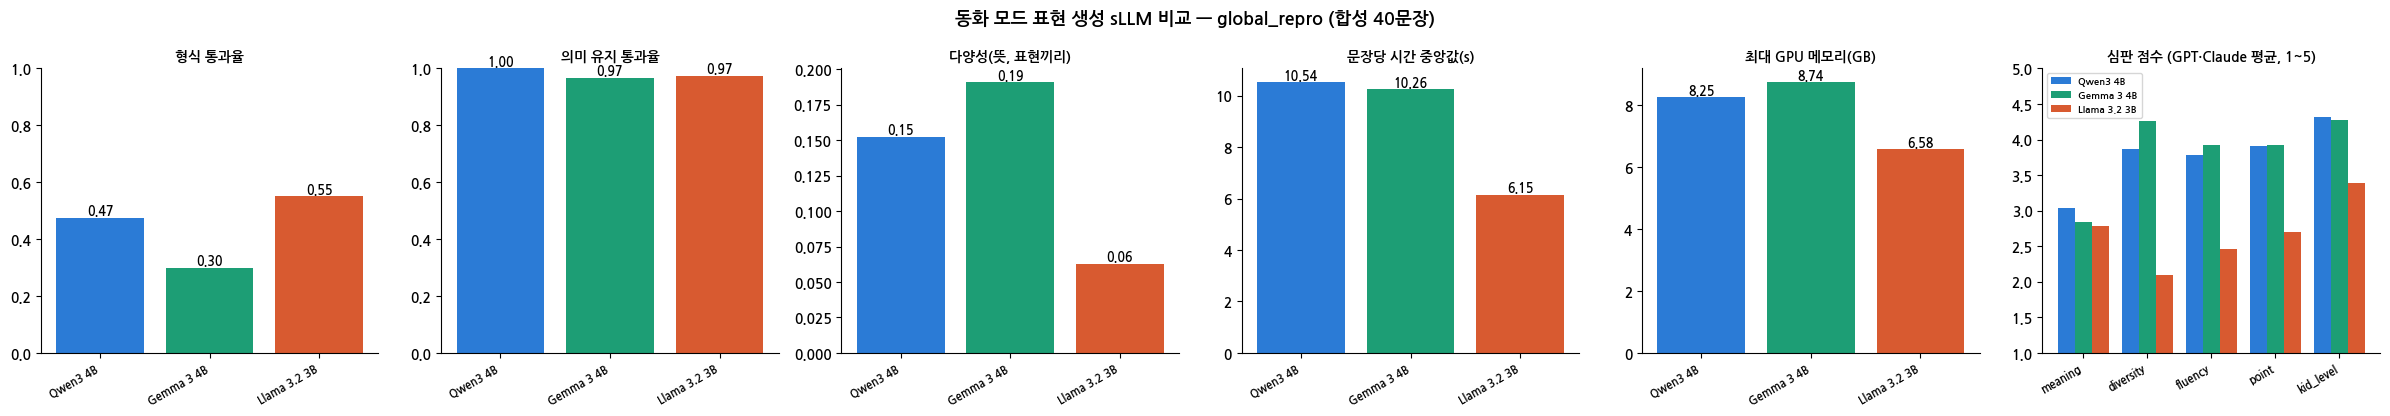

In [10]:
# [셀 7] 그래프 → compare.png
import matplotlib.pyplot as plt, matplotlib.font_manager as fm
nanum = [p for p in fm.findSystemFonts() if "NanumGothic" in p]
if nanum:
    fm.fontManager.addfont(nanum[0]); plt.rcParams["font.family"] = fm.FontProperties(fname=nanum[0]).get_name()
plt.rcParams["axes.unicode_minus"] = False

panels = [("형식 통과율", (0, 1)), ("의미 유지 통과율", (0, 1)), ("다양성(뜻, 표현끼리)", None),
          ("문장당 시간 중앙값(s)", None), ("최대 GPU 메모리(GB)", None)]
colors = ["#2B7BD6", "#1D9E75", "#D85A30"][:len(summary)]
fig, axes = plt.subplots(1, len(panels) + 1, figsize=(4 * (len(panels) + 1), 4.2))
for ax, (col, lim) in zip(axes, panels):
    ax.bar(range(len(summary)), summary[col], color=colors)
    for x, y in enumerate(summary[col]):
        ax.text(x, y, f"{y:.2f}", ha="center", va="bottom", fontsize=9)
    ax.set_xticks(range(len(summary))); ax.set_xticklabels(summary.index, rotation=30, ha="right", fontsize=8)
    ax.set_title(col, fontsize=10); ax.spines[["top", "right"]].set_visible(False)
    if lim: ax.set_ylim(*lim)
ax, w = axes[-1], 0.8 / len(summary)
for i, (name, row) in enumerate(summary[[f"심판 {k}" for k in J_KEYS]].iterrows()):
    ax.bar(np.arange(len(J_KEYS)) + i * w, row.values, w, label=name, color=colors[i])
ax.set_xticks(np.arange(len(J_KEYS)) + w * (len(summary) - 1) / 2); ax.set_xticklabels(J_KEYS, rotation=30, ha="right", fontsize=8)
ax.set_ylim(1, 5); ax.set_title("심판 점수 (GPT·Claude 평균, 1~5)", fontsize=10); ax.legend(fontsize=7)
ax.spines[["top", "right"]].set_visible(False)
fig.suptitle(f"동화 모드 표현 생성 sLLM 비교 — {VARIANT}_{TAG} (합성 {len(SENTENCES)}문장)", fontsize=13)
fig.tight_layout(); fig.savefig(f"{OUT}/compare.png", dpi=150, bbox_inches="tight"); plt.show()

In [11]:
# [셀 8] 사람이 읽어 보기 — ① 처음 8문장 모델별 출력  ② 모델 간 심판 점수가 가장 크게 갈린 5문장
def show(i, with_judge=False):
    print(f"\n### {SENTENCES[i]}")
    for _, r in m[m.id == i].iterrows():
        if not r["texts"]:
            print(f"  [{LABEL[r['model']]}] 형식 실패: {r['raw'][:100]}"); continue
        head = f"  [{LABEL[r['model']]}]" + (f" 심판 평균 {r[J_KEYS].mean():.1f}" if with_judge else "")
        print(head + "".join(f"\n     · {t}\n       → {p}" for t, p in zip(r["texts"], r["points"])))
        if with_judge: print(f"     심판: {r['reason']}")

for i in range(8): show(i)
print("\n\n========== 심판 점수가 가장 크게 갈린 문장 ==========")
spread = m.assign(j=m[J_KEYS].mean(axis=1)).groupby("id")["j"].agg(lambda x: x.max() - x.min())
for i in spread.sort_values(ascending=False).index[:5]: show(i, with_judge=True)


### 아침에 엄마랑 김밥을 만들었다.
  [Qwen3 4B]
     · 아침에 엄마랑 김밥을 만들며 빨래를 봤어요.
       → 김밥을 만들 때 빨래를 봤다는 흉내 내는 말로 생동감을 더했어요.
     · 아침에 엄마랑 김밥을 만들고, 냄새가 맡기까지 기다렸어요.
       → 냄새가 맡기까지 기다렸다는 말로 감각을 더해 재미있게 만들었어요.
  [Gemma 3 4B]
     · 아침 해가 쨍쨍한 날, 엄마랑 맛있는 김밥을 예쁘게 만들었다.
       → 날씨와 김밥을 예쁘게 만들었다는 묘사를 더해서 더 생생하게 느껴지네요.
     · 아침 일찍 엄마랑 함께 김밥을 만들면서 즐거운 시간을 보냈다.
       → 함께 시간을 보냈다는 내용을 넣어서 엄마와의 즐거운 추억을 더 잘 표현했어요.
  [Llama 3.2 3B]
     · 아침에 엄마와 함께 김밥을 만들었다.
       → '와 함께'를 넣어서 엄마와 아이가 함께 한 장면을 보여요.
     · 아침에 엄마가 meokbal을 만들었다.
       → 'meokbal'이라는 단어를 사용해서 아이가 엄마가 만들었는지 잘 알려줘요.

### 동생이 내 크레파스를 빌려 갔다.
  [Qwen3 4B] 형식 실패: [{"text": "동생이 내 크레파스를 빌려가서 하루 종일 그림을 그렸다.", "point": "하루 종일 그림을 그렸다"는 말로 동생이 얼마나 재미있게 썼는지 더 생생하게 보여
  [Gemma 3 4B]
     · 동생이가 내 좋아하는 분홍색 크레파스를 조용히 빌려갔다.
       → 어떤 크레파스를 빌려갔는지, 그리고 어떻게 빌려갔는지 묘사해서 더 생생하게 표현했어요.
     · 동생이가 내 크레파스를 빌려가서 그림을 그리기 시작했다.
       → 동생이가 크레파스를 빌려간 후 무엇을 했는지 덧붙여서 이야기가 더 이어질 수 있도록 만들었어요.
  [Llama 3.2 3B]
     · 동생이 내 크레파스를 빌려가서 맛있게 먹었다.
       → '빌려가서'를 넣어

In [12]:
# [셀 9] 재현 확인 — 어제 결과(PREV_TAG)와 비교
prev = f"{ROOT}/{VARIANT}_{PREV_TAG}"
if TAG == PREV_TAG or not os.path.exists(prev):
    print("비교할 어제 결과가 없음:", prev)
else:
    # 1) 생성 결과가 글자까지 같은지 (탐욕적 디코딩이라 같은 GPU·같은 버전이면 대부분 같아야 함)
    for key in RUN:
        a, b = read_jsonl(f"{prev}/gen_{key}.jsonl"), read_jsonl(f"{OUT}/gen_{key}.jsonl")
        if len(a) and len(b):
            same = (a.sort_values("id")["raw"].values == b.sort_values("id")["raw"].values)
            print(f"{LABEL[key]:24} 생성 결과 일치 {same.sum()}/{len(same)}")
    # 2) 요약표 차이 (오늘 − 어제)
    old = pd.read_csv(f"{prev}/summary.csv", index_col=0)
    diff = (summary - old.reindex(index=summary.index, columns=summary.columns)).T
    display(pd.concat({"오늘": summary.T, "어제": old.reindex(index=summary.index, columns=summary.columns).T, "차이": diff}, axis=1)
              .style.format("{:.3f}"))

Qwen3 4B                 생성 결과 일치 40/40
Gemma 3 4B               생성 결과 일치 40/40
Llama 3.2 3B             생성 결과 일치 23/40


In [1]:
# [셀 10] ①·② 합친 요약 (두 노트북을 모두 돌린 뒤) → summary_all.csv
parts = []
for v, name in [("ko", "① 한국어 특화"), ("global", "② 해외")]:
    p = f"{ROOT}/{v}_{TAG}/summary.csv"
    if os.path.exists(p):
        parts.append(pd.read_csv(p, index_col=0).assign(구분=name))
    else:
        print("아직 없음:", p)
if parts:
    allsum = pd.concat(parts)
    allsum.to_csv(f"{ROOT}/summary_all_{TAG}.csv", encoding="utf-8-sig")
    display(allsum.set_index("구분", append=True).T.style.format("{:.3f}"))